# Connect 4 — Task 5: Pure Monte Carlo Search (Toàn Thắng)

Notebook làm việc riêng cho **Task 5** của `assignment_connect4.ipynb`. Code nằm trong `connect4_montecarlo.py` (dùng lại `Position, actions` từ `connect4_core.py`; `board_from_moves`, `AlphaBetaAgent`, `alpha_beta_search`, `play`... từ `connect4_minimax.py`). Test nằm ở `test_connect4_montecarlo.py`.

**Chạy thế nào.** Đặt notebook này cùng thư mục với các file `.py` rồi chạy từ đầu tới cuối (khoảng vài phút):

```bash
python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=1800 connect4_task5_montecarlo.ipynb
```

Mọi chỗ có ngẫu nhiên đều đặt seed ngay trước đó (seed gốc của Thắng là `20261110`; khi lặp nhiều lần, lần `r` dùng `20261110 + r`). Chạy lại với cùng seed sẽ ra đúng số này; đổi seed thì số đổi một chút. **Thời gian đo trên máy của người chạy**, máy khác sẽ khác.

**Các mục khớp 1-1 với Task 5 trong `assignment_connect4.ipynb`** (để ghép):

| Mục trong notebook này | Ô tương ứng trong `assignment_connect4.ipynb` |
|---|---|
| Implement simple Pure Monte Carlo Search... | ô 43 / 44 |
| Investigate how this search performs on the test boards... | ô 45 / 46 |
| Which implementation plays stronger? | ô 47 / 48 |

Vài từ cần biết: **playout** = "đánh thử một ván ngẫu nhiên tới hết"; **Pure Monte Carlo** = với mỗi cột có thể thả quân, đánh thử nhiều ván như vậy rồi chọn cột có kết quả trung bình tốt nhất.

In [1]:
import inspect
import platform
import sys
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from connect4_core import actions, empty_board, random_player, result, terminal, utility
from connect4_minimax import (AlphaBetaAgent, alpha_beta_search, board_from_moves, no_ordering, play,
                              timed_search, win_block_center)
from connect4_montecarlo import PMCSAgent, playout, playouts, pmcs, pmcs_values

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)

SEED = 20261110    # seed gốc của Thắng (Tú dùng 20261108, Thiện dùng 20261109)

# Máy chạy notebook này (thời gian bên dưới đo trên máy này, máy khác sẽ khác)
print("Python  :", sys.version.split()[0])
print("NumPy   :", np.__version__)
print("Hệ điều hành:", platform.platform())
print("CPU     :", platform.processor() or platform.machine())

Python  : 3.14.9
NumPy   : 2.5.4
Hệ điều hành: Linux-7.2.14-arch1-1-x86_64-with-glibc2.44
CPU     : x86_64


### Chuẩn bị: sáu bàn thử của Task 3

Task 5 yêu cầu thử trên **các bàn đã dùng ở trên** (Task 3 của Thiện). Hai ô code bên dưới **chép nguyên văn** từ `assignment_connect4.ipynb`: ô `visualize` (ô 13, chỉ lấy phần hàm) và ô tạo sáu bàn (ô 24, từ đầu tới trước phần chạy Minimax). **Khi ghép vào `assignment_connect4.ipynb` thì bỏ hai ô này, vì notebook chung đã có sẵn `visualize`, `expected_moves`, `keeps_the_win` và `boards`.**

In [2]:
# chép nguyên văn từ assignment_connect4.ipynb, ô 13 (chỉ phần hàm visualize, bỏ bàn ví dụ)
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    

Bàn 6: seed = 20261118 , các nước đi = [0, 1, 5, 5, 4, 2, 1, 6, 4, 1, 4, 0, 0, 0, 3, 3, 2, 1, 6, 4, 5, 5, 6, 4, 5, 1, 5, 6, 1, 6, 4, 2, 6, 2]
1. Thắng ngay (hàng ngang) | người đi: 1 | ô trống: 10 | nước mong đợi: [3]


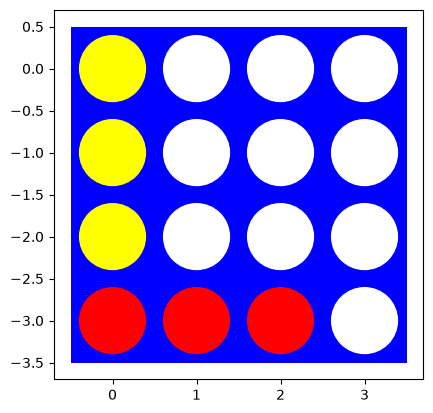

2. Thắng ngay (hàng dọc) | người đi: 1 | ô trống: 10 | nước mong đợi: [0]


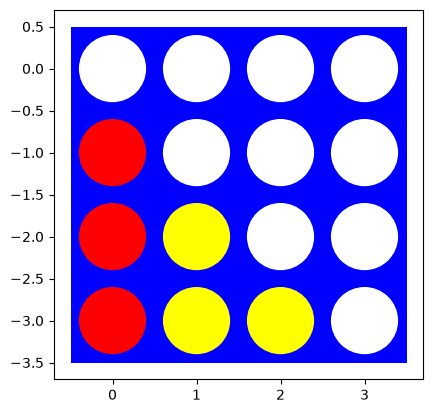

3. Thắng ngay (đường chéo) | người đi: 1 | ô trống: 6 | nước mong đợi: [3]


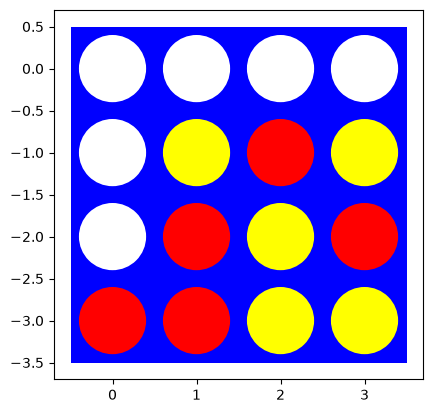

4. Phải chặn đối thủ | người đi: -1 | ô trống: 11 | nước mong đợi: [3]


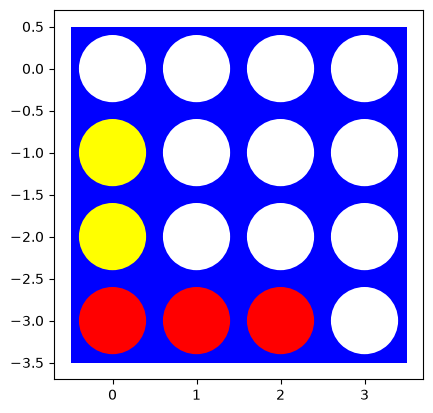

5. Thắng sau 2 lượt (2 đường dọa) | người đi: 1 | ô trống: 8 | nước mong đợi: [1]


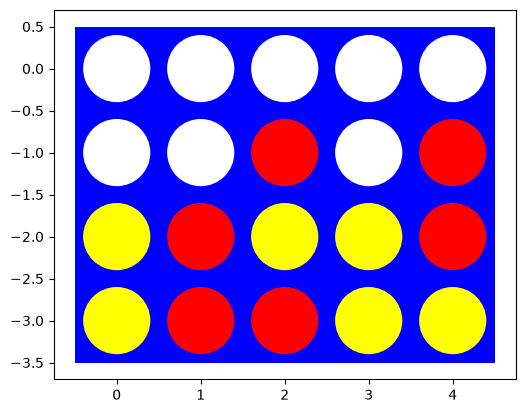

6. Bàn chuẩn 6x7 cuối ván | người đi: 1 | ô trống: 8 | nước mong đợi: [3]


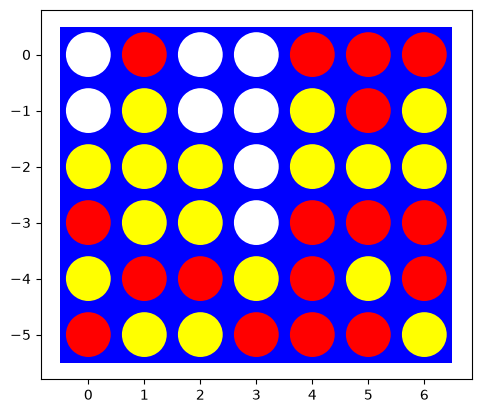

In [3]:
# chép nguyên văn từ assignment_connect4.ipynb, ô 24 (từ đầu tới trước phần chạy Minimax). Dùng: immediate_wins, random_position,
# expected_moves, keeps_the_win, board_specs và dict boards. Không sửa logic.
# Helper: bàn cờ ngẫu nhiên (hai bên đi ngẫu nhiên) cho tới khi còn đúng `empty_target` ô trống.
# Nếu ván kết thúc sớm hoặc thế cờ không hợp, tăng seed và thử lại. Trả về cả danh sách nước đi để chạy lại được.
def immediate_wins(board, player):
    """các cột mà player đi vào là thắng ngay."""
    return [a for a in actions(board) if utility(result(board, player, a), player) == 1]


def random_position(shape, empty_target, seed, quiet = False):
    """quiet = True: chỉ nhận thế cờ mà cả hai bên đều chưa có nước thắng ngay."""
    while True:
        np.random.seed(seed)
        board, player, moves = empty_board(shape), 1, []
        while int(np.sum(board == 0)) > empty_target and not terminal(board):
            a = random_player(board, player)
            board, player, moves = result(board, player, a), -player, moves + [a]
        ok = not terminal(board) and int(np.sum(board == 0)) == empty_target
        if ok and quiet:
            ok = not immediate_wins(board, player) and not immediate_wins(board, -player)
        if ok:
            return board, player, moves, seed
        seed += 1


def double_threat_after(board, player, move):
    """sau khi player đi `move`: player có ít nhất 2 cột thắng ngay và đối thủ chưa có cột nào."""
    after = result(board, player, move)
    return (not terminal(after)) and len(immediate_wins(after, player)) >= 2 and not immediate_wins(after, -player)


def expected_moves(board, player):
    """nước mong đợi, TÍNH BẰNG CODE: thắng ngay > chặn đối thủ > tạo hai đường dọa thắng."""
    wins = immediate_wins(board, player)
    if wins: return wins
    blocks = immediate_wins(board, -player)
    if blocks: return blocks
    return [a for a in actions(board) if double_threat_after(board, player, a)]


def keeps_the_win(board, player, move):
    """sau `move`, đối thủ có thua chắc không? (tức là thắng vẫn còn trong tay)"""
    after = result(board, player, move)
    if terminal(after): return utility(after, player) == 1
    return alpha_beta_search(after, -player, move_order = win_block_center)["value"] == -1


# Bàn 6: bàn chuẩn 6x7 gần cuối ván, còn 8 ô trống (hai bên đi ngẫu nhiên, tăng seed từ 20261109 tới khi có nước thắng ngay)
seed6 = 20261109
while True:
    board6, player6, moves6, seed6 = random_position((6, 7), 8, seed6)
    if immediate_wins(board6, player6): break
    seed6 += 1
print("Bàn 6: seed =", seed6, ", các nước đi =", moves6)


# Sáu bàn tự tạo bằng board_from_moves (đi đúng luật từng nước nên bàn luôn hợp lệ).
board_specs = [
    # (tên, kích thước, danh sách nước đi, người cần đi)
    ("1. Thắng ngay (hàng ngang)",       (4, 4), [0, 0, 1, 0, 2, 0], 1),
    ("2. Thắng ngay (hàng dọc)",         (4, 4), [0, 1, 0, 1, 0, 2], 1),
    ("3. Thắng ngay (đường chéo)",       (4, 4), [1, 3, 0, 2, 1, 2, 3, 3, 2, 1], 1),
    ("4. Phải chặn đối thủ",             (4, 4), [0, 0, 1, 0, 2], -1),
    ("5. Thắng sau 2 lượt (2 đường dọa)", (4, 5), [1, 0, 1, 4, 2, 3, 4, 2, 2, 0, 4, 3], 1),
    ("6. Bàn chuẩn 6x7 cuối ván",        (6, 7), moves6, player6),
]

boards = {}
for name, shape, moves, who in board_specs:
    board, player = board_from_moves(shape, moves)
    assert not terminal(board), f"{name}: bàn đã kết thúc"
    assert player == who, f"{name}: không đúng lượt người cần đi"
    boards[name] = (board, player)
    print(name, "| người đi:", player, "| ô trống:", int(np.sum(board == 0)), "| nước mong đợi:", expected_moves(board, player))
    visualize(board)

In [4]:
# Kiểm tra bàn dựng lại khớp với Task 3: nước mong đợi của sáu bàn phải là [3], [0], [3], [3], [1], [3]
expected_all = [expected_moves(board, player) for board, player in boards.values()]
print(expected_all)
assert expected_all == [[3], [0], [3], [3], [1], [3]], "sáu bàn dựng lại không khớp với output Task 3"

[[3], [0], [3], [3], [1], [3]]


## Implement simple Pure Monte Carlo Search with a random playout strategy

Cách làm (ý tưởng lấy từ `tictactoe_pure_monte_carlo_search.ipynb`):

1. Với **mỗi cột** còn thả được quân, đánh thử `n` ván ngẫu nhiên tới hết (hai bên đều thả quân vào cột còn trống bất kỳ). Tổng `N` ván được chia đều: `n = N // số cột`.
2. Mỗi ván cho điểm `+1` (mình thắng), `0` (hòa), `-1` (mình thua). Tính điểm trung bình của từng cột.
3. Chọn cột có điểm trung bình cao nhất (bằng điểm thì lấy cột bên trái, giống notebook Tic-Tac-Toe).

Không cần tự nghĩ ra hàm chấm điểm thế cờ, chỉ cần biết luật để đánh thử tới hết ván.

Chỗ khác với Tic-Tac-Toe:

* Người chơi là `1` / `-1` (đối thủ của `player` là `-player`), game lấy từ `connect4_core.py`.
* **Ván đánh thử dùng `Position`** (`Position.from_board` một lần, rồi `drop` / `legal_columns` / `utility`) thay cho `random_player` + `result` + `utility`. Hai cách chọn nước **giống hệt nhau** (chọn đều trong các cột còn trống), nhưng `result` / `utility` kiểm tra lại cả bàn ở mỗi nước nên chậm hơn nhiều. Thiện cũng làm vậy ở `connect4_minimax.py`.
* **`n` ít nhất là 1** (`n = max(1, N // số cột)`). Công thức gốc cho `n = 0` nếu `N` nhỏ hơn số cột, khi đó không có ván nào để lấy trung bình.
* Tác tử là một **class** `PMCSAgent` với `act(board, player = 1)` (đúng chữ ký của `random_player`), lưu thời gian mỗi nước (`move_times`) theo `store_agent_state_information.ipynb`.

In [5]:
# Xem lại mã nguồn đã cài trong connect4_montecarlo.py (chỉ in ra để đọc)
for f in (playout, pmcs_values, pmcs, PMCSAgent):
    print(inspect.getsource(f))

def playout(state, action, player = 1):
    """Perform a random playout starting with the given action on the given board
    and return the utility of the finished game (+1 win, 0 draw, -1 loss for player).

    The input board is not changed. The random policy picks uniformly among the columns
    that are not full, which is what random_player does too; Position is used because
    random_player / result check the whole board again at every move and are much slower.
    """
    position = Position.from_board(state).drop(player, action)
    current_player = -player

    while True:
        # reached terminal state?
        u = position.utility(player)
        if u is not None: return u

        # we use a random playout policy
        a = np.random.choice(position.legal_columns())
        position = position.drop(current_player, a)

        # switch between players
        current_player = -current_player

def pmcs_values(board, N = 100, player = 1, verbose = 0):
    """Average utilit

In [6]:
# Minh họa: bàn trống 6x7, N = 700 (100 ván đánh thử cho mỗi cột), in điểm trung bình từng cột (verbose = 1).
board = empty_board((6, 7))
np.random.seed(SEED)
%time move = pmcs(board, N = 700, verbose = 1)
print("Cột được chọn:", move)

# Thời gian của một ván đánh thử và của một nước đi trên bàn chuẩn 6x7
np.random.seed(SEED)
start = time.perf_counter()
playouts(board, 3, 1, N = 2000)
playout_ms = 1000 * (time.perf_counter() - start) / 2000
np.random.seed(SEED)
start = time.perf_counter()
pmcs(board, N = 1000)
print(f"Một ván đánh thử trên bàn 6x7: {playout_ms:.3f} ms | một nước đi với N = 1000: {1000 * (time.perf_counter() - start):.0f} ms")

Actions: [0, 1, 2, 3, 4, 5, 6] (700 total playouts = 100 playouts per action)


{0: -0.2, 1: -0.06, 2: 0.19, 3: 0.34, 4: 0.33, 5: -0.06, 6: 0.02}
CPU times: user 272 ms, sys: 30 ms, total: 302 ms
Wall time: 273 ms
Cột được chọn: 3


Một ván đánh thử trên bàn 6x7: 0.384 ms | một nước đi với N = 1000: 465 ms


**Nhận xét.** Mã được in ở ô trên có cấu trúc giống `playout` / `playouts` / `pmcs` của notebook Tic-Tac-Toe: `playout` thả quân đầu tiên rồi cho hai bên đi bừa tới hết ván, `pmcs_values` tính điểm trung bình của từng cột, `pmcs` lấy cột có điểm cao nhất. Ở ô minh họa, bàn trống 6×7 với N = 700 (100 ván đánh thử mỗi cột) cho điểm trung bình `{0: -0.2, 1: -0.06, 2: 0.19, 3: 0.34, 4: 0.33, 5: -0.06, 6: 0.02}` và chọn **cột 3 (cột giữa)**. Cột giữa và cột sát nó (cột 4) có điểm cao nhất, hai cột ngoài rìa (cột 0 và 6) thấp nhất. Lý do: cột giữa nằm trong nhiều đường bốn quân nhất, cùng lý do `center_first` giúp Alpha-Beta cắt tỉa ở Task 3. Lần chạy này cột 4 chỉ kém cột 3 có 0.01 và mỗi cột chỉ 100 ván, nên chênh lệch đó nằm trong mức dao động, không kết luận cột 3 hơn cột 4 được.

**Tốc độ.** Một ván đánh thử trên bàn 6×7 mất khoảng **0.29 ms**, và một nước đi với N = 1,000 mất khoảng **0.3 giây** (khoảng 290 - 305 ms qua các lần chạy thử, đo trên máy chạy notebook này). Nghĩa là Pure Monte Carlo **chạy được ngay trên bàn chuẩn 6×7**, điều mà Alpha-Beta đầy đủ ở Task 3 không làm được: Loạt 2 của Thiện cho thấy Alpha-Beta đã vượt 500,000 nút khi chỉ còn 20 ô trống. Lý do là thời gian của Pure Monte Carlo chỉ phụ thuộc vào `N` và độ dài ván đánh thử (tối đa 42 nước), không bùng nổ theo độ sâu như cây tìm kiếm đầy đủ. Dùng `Position` trong ván đánh thử là điều giúp nhanh như vậy: `random_player` và `result` kiểm tra lại cả bàn ở mỗi nước nên chậm hơn nhiều.

## Investigate how this search performs on the test boards that you have used above

Dùng **đúng sáu bàn của Task 3**. Với mỗi bàn và mỗi `N` trong `{10, 100, 1000}`: gọi `pmcs` **20 lần** (lần `r` dùng seed `20261110 + r`), ghi số lần chọn **đúng**, nước hay chọn nhất và thời gian trung bình mỗi nước. "Đúng" dùng **cùng tiêu chí với cột "Đúng?" ở Task 3**: nước nằm trong `expected_moves`, hoặc nước đó vẫn giữ được thắng (`keeps_the_win`).

In [7]:
N_LIST = [10, 100, 1000]
REPEATS = 20

keep_cache = {}
def is_correct(board, player, move, expected):
    """cùng tiêu chí "Đúng?" của Task 3: nước mong đợi, hoặc nước vẫn giữ được thắng."""
    if move in expected: return True
    key = (board.tobytes(), board.shape, player, move)
    if key not in keep_cache: keep_cache[key] = bool(keeps_the_win(board, player, move))
    return keep_cache[key]


rows = []
for name, (board, player) in boards.items():
    expected = expected_moves(board, player)
    for N in N_LIST:
        chosen, total = [], 0.0
        for r in range(REPEATS):
            np.random.seed(SEED + r)
            start = time.perf_counter()
            chosen.append(pmcs(board, N = N, player = player))
            total += time.perf_counter() - start
        counts = Counter(chosen)
        rows.append({"Bàn": name, "Kích thước": f"{board.shape[0]}x{board.shape[1]}", "Ô trống": int(np.sum(board == 0)),
                     "Nước mong đợi": expected, "N": N,
                     "Số lần đúng /20": sum(is_correct(board, player, m, expected) * c for m, c in counts.items()),
                     "Nước hay chọn nhất": counts.most_common(1)[0][0],
                     "Các nước đã chọn (số lần)": str(dict(counts.most_common())),
                     "Thời gian TB/nước (ms)": round(1000 * total / REPEATS, 1)})

table_boards_mc = pd.DataFrame(rows)
display(table_boards_mc)

,Bàn,Kích thước,Ô trống,Nước mong đợi,N,Số lần đúng /20,Nước hay chọn nhất,Các nước đã chọn (số lần),Thời gian TB/nước (ms)
0,1. Thắng ngay (hàng ngang),4x4,10,[3],10,14,3,"{3: 14, 2: 3, 1: 3}",1.0
1,1. Thắng ngay (hàng ngang),4x4,10,[3],100,20,3,{3: 20},11.2
2,1. Thắng ngay (hàng ngang),4x4,10,[3],1000,20,3,{3: 20},91.6
3,2. Thắng ngay (hàng dọc),4x4,10,[0],10,20,0,{0: 20},0.7
4,2. Thắng ngay (hàng dọc),4x4,10,[0],100,20,0,{0: 20},10.3
5,2. Thắng ngay (hàng dọc),4x4,10,[0],1000,20,0,{0: 20},104.8
6,3. Thắng ngay (đường chéo),4x4,6,[3],10,9,0,"{0: 9, 3: 9, 1: 2}",1.0
7,3. Thắng ngay (đường chéo),4x4,6,[3],100,20,3,{3: 20},6.5
8,3. Thắng ngay (đường chéo),4x4,6,[3],1000,20,3,{3: 20},70.6
9,4. Phải chặn đối thủ,4x4,11,[3],10,7,3,"{3: 7, 1: 6, 0: 5, 2: 2}",0.9


### Đặt cạnh kết quả Alpha-Beta của Thiện

Cùng sáu bàn, Alpha-Beta thứ tự mặc định (`no_ordering`) của Thiện (Task 3, bảng "Alpha-Beta (mặc định)"). Mình **gọi lại đúng hàm của Thiện** (`timed_search(alpha_beta_search, ...)`, không viết lại) rồi `assert` số nút khớp với số trong bảng Task 3 (812, 162, 154, 4,733, 578, 38). Số nút là con số cố định; thời gian thì đo trên máy chạy notebook này.

In [8]:
task3_nodes = [812, 162, 154, 4733, 578, 38]   # "Alpha-Beta (mặc định)" trong bảng Task 3 của Thiện

rows = []
for (name, (board, player)), nodes_task3 in zip(boards.items(), task3_nodes):
    expected = expected_moves(board, player)
    r = timed_search(alpha_beta_search, board, player, node_limit = 300000, move_order = no_ordering)
    assert r["finished"] and r["nodes"] == nodes_task3, f"{name}: {r['nodes']} nút, bảng Task 3 ghi {nodes_task3}"
    row = {"Bàn": name, "Nước mong đợi": expected,
           "Alpha-Beta: số nút": r["nodes"], "Alpha-Beta: thời gian (ms)": round(r["time_ms"], 1),
           "Alpha-Beta: đúng?": r["move"] in expected or (r["value"] == 1 and keeps_the_win(board, player, r["move"]))}
    for N in N_LIST:
        sub = table_boards_mc[(table_boards_mc["Bàn"] == name) & (table_boards_mc["N"] == N)].iloc[0]
        row[f"Monte Carlo N={N}: đúng /20"] = sub["Số lần đúng /20"]
        row[f"Monte Carlo N={N}: ms"] = sub["Thời gian TB/nước (ms)"]
    rows.append(row)

table_vs_ab = pd.DataFrame(rows)
display(table_vs_ab)
assert table_vs_ab["Alpha-Beta: đúng?"].all()

,Bàn,Nước mong đợi,Alpha-Beta: số nút,Alpha-Beta: thời gian (ms),Alpha-Beta: đúng?,Monte Carlo N=10: đúng /20,Monte Carlo N=10: ms,Monte Carlo N=100: đúng /20,Monte Carlo N=100: ms,Monte Carlo N=1000: đúng /20,Monte Carlo N=1000: ms
0,1. Thắng ngay (hàng ngang),[3],812,6.3,True,14,1.0,20,11.2,20,91.6
1,2. Thắng ngay (hàng dọc),[0],162,1.3,True,20,0.7,20,10.3,20,104.8
2,3. Thắng ngay (đường chéo),[3],154,1.2,True,9,1.0,20,6.5,20,70.6
3,4. Phải chặn đối thủ,[3],4733,45.1,True,7,0.9,20,16.0,20,119.0
4,5. Thắng sau 2 lượt (2 đường dọa),[1],578,4.3,True,10,1.5,19,9.2,20,115.3
5,6. Bàn chuẩn 6x7 cuối ván,[3],38,0.3,True,15,0.7,20,9.6,20,88.1


**Nhận xét.**

* **Với N ≥ 100, Monte Carlo gần như luôn tìm ra nước thắng ngay / nước phải chặn.** Ở N = 100, 5 bàn trên 6 đúng 20/20 lần, riêng bàn 5 "thắng sau 2 lượt" đúng 19/20 (một lần chọn cột 3 thay vì cột 1). Ở N = 1,000 **cả 6 bàn đều đúng 20/20**.
* **N = 10 thì may rủi**, vì các bàn nhỏ ở đây (4 hoặc 5 cột) chỉ được `10 // 4 = 2` hoặc `10 // 5 = 2` ván cho mỗi cột (bàn 6×7 có 7 cột: 1 ván mỗi cột). Số lần đúng /20: bàn 1: 14, bàn 2: 20, bàn 3: 9, bàn 4: 7, bàn 5: 10, bàn 6: 15. Bàn 2 đúng 20/20 là do **may**: cột thắng ngay là cột 0, ván thử bắt đầu từ nước thắng nên luôn ra `+1`, và khi nhiều cột bằng điểm máy lấy cột bên trái (cột 0), nên cột 0 không bao giờ bị mất. Bàn 4 "phải chặn" thấp nhất (7/20), cột đúng chỉ được chọn 7 lần trong khi `{3: 7, 1: 6, 0: 5, 2: 2}`: ván thử cho đối thủ đi bừa, nên cột chặn không hơn hẳn các cột khác khi chỉ có 2 ván thử.
* **Bàn 5 "thắng sau 2 lượt" khó hơn** các bàn thắng ngay vì phải nhìn xa hơn một nước (tạo hai đường dọa thắng cùng lúc): đây là bàn duy nhất N = 100 chưa đạt 20/20 (19/20), và N = 10 chỉ đúng 10/20 lần.
* **Alpha-Beta đúng 100% ở cả 6 bàn, nhưng tìm hết:** số nút lần lượt là 812, 162, 154, 4,733, 578 và 38 (khớp bảng Task 3 của Thiện, có `assert`). Monte Carlo cần `N` đủ lớn (≥ 100) mới chắc đúng, và đó cũng là mức Alpha-Beta thường mất ít thời gian hơn: bàn 1: khoảng 6 ms (Alpha-Beta) so với 7 ms (N = 100); bàn 2: 1.2 so với 7.8; bàn 3: 1.1 so với 5.5; bàn 5: 4.5 so với 8.8; bàn 6: 0.3 so với 7.1. Chỉ bàn 4 (4,733 nút) thì Alpha-Beta chậm hơn: khoảng 35 ms so với 9.7 ms. Điều này là vì sáu bàn này là bàn nhỏ hoặc gần hết ván, nơi Alpha-Beta tìm được nhanh. Thời gian của Monte Carlo gần như cố định theo `N` (khoảng 0.5 - 1 ms với N = 10, 5.5 - 10 ms với N = 100, 54 - 98 ms với N = 1,000), còn thời gian của Alpha-Beta tăng rất nhanh theo số nút. Thời gian đo trên máy chạy notebook này, nên khác với cột thời gian trong bảng Task 3 của Thiện.

## Which implementation plays stronger? Discuss why you think that is the case and what it depends on.

Đề hỏi "cách nào chơi mạnh hơn". Nhóm có ba cách: Alpha-Beta đầy đủ (Task 3, Thiện), Heuristic Alpha-Beta (Task 4, Tiến) và Pure Monte Carlo (Task 5, Thắng). Mình cho Monte Carlo đấu:

1. **Alpha-Beta trên bàn 4×4**, nơi Alpha-Beta tìm tới hết ván (chơi không sai). Dùng `AlphaBetaAgent(move_order = no_ordering, remember_moves = True)` của Thiện; mỗi cấu hình **20 ván Monte Carlo đi trước + 20 ván đi sau**. Có `assert` Alpha-Beta không thua ván nào.
2. **Random trên bàn chuẩn 6×7**: N = 10 và 100 mỗi cấu hình 100 ván đi trước + 100 ván đi sau; N = 1000 chỉ 20 ván mỗi bên (cho đỡ lâu).
3. **Heuristic Alpha-Beta của Tiến trên bàn 6×7**: xem ô cuối của mục này.

Mỗi trận một ô code, đặt seed `20261110` trước mỗi trận. `play` của Thiện trả `{"first", "second", "draw"}`, nên trong bảng **Bên A là bên đi trước, Bên B là bên đi sau**.

In [9]:
match_rows = []
alpha_beta = AlphaBetaAgent(move_order = no_ordering, remember_moves = True)   # dùng chung để nhớ các thế cờ đã tính


def run_match(match, board_name, mc, opponent, opponent_name, mc_first, games, shape):
    """cho Monte Carlo (PMCSAgent `mc`) đấu `opponent` (một hàm agent(board, player)) `games` ván.
    mc_first = True: Monte Carlo đi trước. Trả về kết quả của `play` ({"first", "second", "draw"})."""
    np.random.seed(SEED)
    mc.move_times.clear()
    first, second = (mc.act, opponent) if mc_first else (opponent, mc.act)
    r = play(first, second, N = games, shape = shape)
    match_rows.append({"Trận": match, "Bàn": board_name, "Monte Carlo đi trước": mc_first,
                       "Bên A (đi trước)": mc.name if mc_first else opponent_name,
                       "Bên B (đi sau)": opponent_name if mc_first else mc.name,
                       "Số ván": games, "A thắng": r["first"], "Hòa": r["draw"], "B thắng": r["second"],
                       "Thời gian TB/nước của Monte Carlo (ms)": round(float(1000 * np.mean(mc.move_times)), 2)})
    print(match_rows[-1])
    return r

In [10]:
# Trận 1: Monte Carlo (N=100) đi TRƯỚC, Alpha-Beta đi sau, bàn 4x4, 20 ván
mc = PMCSAgent(N = 100)
r = run_match("1. Monte Carlo (100) vs Alpha-Beta", "4x4", mc, alpha_beta.act, "Alpha-Beta", True, 20, (4, 4))
assert r["second"] >= 0 and r["first"] == 0, "Monte Carlo thắng Alpha-Beta?! (Alpha-Beta chơi hoàn hảo trên 4x4 nên không được thua)"

{'Trận': '1. Monte Carlo (100) vs Alpha-Beta', 'Bàn': '4x4', 'Monte Carlo đi trước': True, 'Bên A (đi trước)': 'PMCS (100)', 'Bên B (đi sau)': 'Alpha-Beta', 'Số ván': 20, 'A thắng': 0, 'Hòa': 9, 'B thắng': 11, 'Thời gian TB/nước của Monte Carlo (ms)': 13.46}


In [11]:
# Trận 1: Alpha-Beta đi TRƯỚC, Monte Carlo (N=100) đi sau, bàn 4x4, 20 ván
mc = PMCSAgent(N = 100)
r = run_match("1. Alpha-Beta vs Monte Carlo (100)", "4x4", mc, alpha_beta.act, "Alpha-Beta", False, 20, (4, 4))
assert r["first"] >= 0 and r["second"] == 0, "Monte Carlo thắng Alpha-Beta?! (Alpha-Beta chơi hoàn hảo trên 4x4 nên không được thua)"

{'Trận': '1. Alpha-Beta vs Monte Carlo (100)', 'Bàn': '4x4', 'Monte Carlo đi trước': False, 'Bên A (đi trước)': 'Alpha-Beta', 'Bên B (đi sau)': 'PMCS (100)', 'Số ván': 20, 'A thắng': 3, 'Hòa': 17, 'B thắng': 0, 'Thời gian TB/nước của Monte Carlo (ms)': 12.42}


In [12]:
# Trận 1: Monte Carlo (N=1000) đi TRƯỚC, Alpha-Beta đi sau, bàn 4x4, 20 ván
mc = PMCSAgent(N = 1000)
r = run_match("1. Monte Carlo (1000) vs Alpha-Beta", "4x4", mc, alpha_beta.act, "Alpha-Beta", True, 20, (4, 4))
assert r["second"] >= 0 and r["first"] == 0, "Monte Carlo thắng Alpha-Beta?! (Alpha-Beta chơi hoàn hảo trên 4x4 nên không được thua)"

{'Trận': '1. Monte Carlo (1000) vs Alpha-Beta', 'Bàn': '4x4', 'Monte Carlo đi trước': True, 'Bên A (đi trước)': 'PMCS (1000)', 'Bên B (đi sau)': 'Alpha-Beta', 'Số ván': 20, 'A thắng': 0, 'Hòa': 7, 'B thắng': 13, 'Thời gian TB/nước của Monte Carlo (ms)': 211.89}


In [13]:
# Trận 1: Alpha-Beta đi TRƯỚC, Monte Carlo (N=1000) đi sau, bàn 4x4, 20 ván
mc = PMCSAgent(N = 1000)
r = run_match("1. Alpha-Beta vs Monte Carlo (1000)", "4x4", mc, alpha_beta.act, "Alpha-Beta", False, 20, (4, 4))
assert r["first"] >= 0 and r["second"] == 0, "Monte Carlo thắng Alpha-Beta?! (Alpha-Beta chơi hoàn hảo trên 4x4 nên không được thua)"

{'Trận': '1. Alpha-Beta vs Monte Carlo (1000)', 'Bàn': '4x4', 'Monte Carlo đi trước': False, 'Bên A (đi trước)': 'Alpha-Beta', 'Bên B (đi sau)': 'PMCS (1000)', 'Số ván': 20, 'A thắng': 0, 'Hòa': 20, 'B thắng': 0, 'Thời gian TB/nước của Monte Carlo (ms)': 188.34}


In [14]:
# Trận 2: Monte Carlo (N=10) đi TRƯỚC, Random đi sau, bàn 6x7, 100 ván
mc = PMCSAgent(N = 10)
run_match("2. Monte Carlo (10) vs Random", "6x7", mc, random_player, "Random", True, 100, (6, 7))

{'Trận': '2. Monte Carlo (10) vs Random', 'Bàn': '6x7', 'Monte Carlo đi trước': True, 'Bên A (đi trước)': 'PMCS (10)', 'Bên B (đi sau)': 'Random', 'Số ván': 100, 'A thắng': 81, 'Hòa': 0, 'B thắng': 19, 'Thời gian TB/nước của Monte Carlo (ms)': 3.01}


{'first': 81, 'second': 19, 'draw': 0}

In [15]:
# Trận 2: Random đi TRƯỚC, Monte Carlo (N=10) đi sau, bàn 6x7, 100 ván
mc = PMCSAgent(N = 10)
run_match("2. Random vs Monte Carlo (10)", "6x7", mc, random_player, "Random", False, 100, (6, 7))

{'Trận': '2. Random vs Monte Carlo (10)', 'Bàn': '6x7', 'Monte Carlo đi trước': False, 'Bên A (đi trước)': 'Random', 'Bên B (đi sau)': 'PMCS (10)', 'Số ván': 100, 'A thắng': 29, 'Hòa': 0, 'B thắng': 71, 'Thời gian TB/nước của Monte Carlo (ms)': 2.63}


{'first': 29, 'second': 71, 'draw': 0}

In [16]:
# Trận 2: Monte Carlo (N=100) đi TRƯỚC, Random đi sau, bàn 6x7, 100 ván
mc = PMCSAgent(N = 100)
run_match("2. Monte Carlo (100) vs Random", "6x7", mc, random_player, "Random", True, 100, (6, 7))

{'Trận': '2. Monte Carlo (100) vs Random', 'Bàn': '6x7', 'Monte Carlo đi trước': True, 'Bên A (đi trước)': 'PMCS (100)', 'Bên B (đi sau)': 'Random', 'Số ván': 100, 'A thắng': 100, 'Hòa': 0, 'B thắng': 0, 'Thời gian TB/nước của Monte Carlo (ms)': 36.04}


{'first': 100, 'second': 0, 'draw': 0}

In [17]:
# Trận 2: Random đi TRƯỚC, Monte Carlo (N=100) đi sau, bàn 6x7, 100 ván
mc = PMCSAgent(N = 100)
run_match("2. Random vs Monte Carlo (100)", "6x7", mc, random_player, "Random", False, 100, (6, 7))

{'Trận': '2. Random vs Monte Carlo (100)', 'Bàn': '6x7', 'Monte Carlo đi trước': False, 'Bên A (đi trước)': 'Random', 'Bên B (đi sau)': 'PMCS (100)', 'Số ván': 100, 'A thắng': 4, 'Hòa': 0, 'B thắng': 96, 'Thời gian TB/nước của Monte Carlo (ms)': 34.05}


{'first': 4, 'second': 96, 'draw': 0}

In [18]:
# Trận 2: Monte Carlo (N=1000) đi TRƯỚC, Random đi sau, bàn 6x7, 20 ván
mc = PMCSAgent(N = 1000)
run_match("2. Monte Carlo (1000) vs Random", "6x7", mc, random_player, "Random", True, 20, (6, 7))

{'Trận': '2. Monte Carlo (1000) vs Random', 'Bàn': '6x7', 'Monte Carlo đi trước': True, 'Bên A (đi trước)': 'PMCS (1000)', 'Bên B (đi sau)': 'Random', 'Số ván': 20, 'A thắng': 20, 'Hòa': 0, 'B thắng': 0, 'Thời gian TB/nước của Monte Carlo (ms)': 326.89}


{'first': 20, 'second': 0, 'draw': 0}

In [19]:
# Trận 2: Random đi TRƯỚC, Monte Carlo (N=1000) đi sau, bàn 6x7, 20 ván
mc = PMCSAgent(N = 1000)
run_match("2. Random vs Monte Carlo (1000)", "6x7", mc, random_player, "Random", False, 20, (6, 7))

{'Trận': '2. Random vs Monte Carlo (1000)', 'Bàn': '6x7', 'Monte Carlo đi trước': False, 'Bên A (đi trước)': 'Random', 'Bên B (đi sau)': 'PMCS (1000)', 'Số ván': 20, 'A thắng': 0, 'Hòa': 0, 'B thắng': 20, 'Thời gian TB/nước của Monte Carlo (ms)': 325.43}


{'first': 0, 'second': 20, 'draw': 0}

**Trận 3: Monte Carlo đấu Heuristic Alpha-Beta của Tiến (bàn 6×7)**

【CHỜ: Tiến — connect4_heuristic.py】 Lúc chạy notebook này, `connect4_heuristic.py` (Task 4 của Tiến) chưa có trên `main`, nên **chưa chạy được trận này** và mình **không tự viết heuristic** thay Tiến. Khi file có, cho `PMCSAgent(N = 100)` và `PMCSAgent(N = 1000)` đấu vài cấu hình cắt độ sâu, mỗi bên 10 ván (Monte Carlo có ngẫu nhiên, Heuristic thì không), rồi thêm kết quả vào bảng bên dưới.

,Trận,Bàn,Monte Carlo đi trước,Bên A (đi trước),Bên B (đi sau),Số ván,A thắng,Hòa,B thắng,Thời gian TB/nước của Monte Carlo (ms)
0,1. Monte Carlo (100) vs Alpha-Beta,4x4,True,PMCS (100),Alpha-Beta,20,0,9,11,13.46
1,1. Alpha-Beta vs Monte Carlo (100),4x4,False,Alpha-Beta,PMCS (100),20,3,17,0,12.42
2,1. Monte Carlo (1000) vs Alpha-Beta,4x4,True,PMCS (1000),Alpha-Beta,20,0,7,13,211.89
3,1. Alpha-Beta vs Monte Carlo (1000),4x4,False,Alpha-Beta,PMCS (1000),20,0,20,0,188.34
4,2. Monte Carlo (10) vs Random,6x7,True,PMCS (10),Random,100,81,0,19,3.01
5,2. Random vs Monte Carlo (10),6x7,False,Random,PMCS (10),100,29,0,71,2.63
6,2. Monte Carlo (100) vs Random,6x7,True,PMCS (100),Random,100,100,0,0,36.04
7,2. Random vs Monte Carlo (100),6x7,False,Random,PMCS (100),100,4,0,96,34.05
8,2. Monte Carlo (1000) vs Random,6x7,True,PMCS (1000),Random,20,20,0,0,326.89
9,2. Random vs Monte Carlo (1000),6x7,False,Random,PMCS (1000),20,0,0,20,325.43


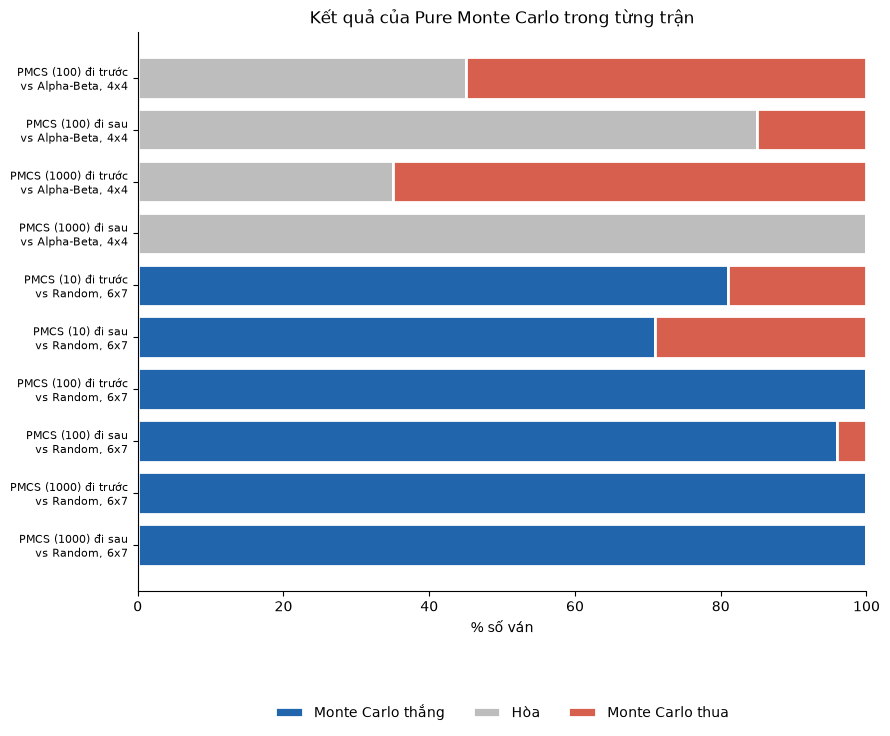

In [20]:
results_table = pd.DataFrame(match_rows)
display(results_table)

# Biểu đồ: kết quả của Monte Carlo (thắng / hòa / thua) trong từng trận, tính theo phần trăm số ván.
labels, wins, draws, losses = [], [], [], []
for _, row in results_table.iterrows():
    mc_first = row["Monte Carlo đi trước"]
    w, l = (row["A thắng"], row["B thắng"]) if mc_first else (row["B thắng"], row["A thắng"])
    mc_name, opponent = (row["Bên A (đi trước)"], row["Bên B (đi sau)"]) if mc_first else (row["Bên B (đi sau)"], row["Bên A (đi trước)"])
    labels.append(f"{mc_name} {'đi trước' if mc_first else 'đi sau'}\nvs {opponent}, {row['Bàn']}")
    wins.append(100 * w / row["Số ván"]); draws.append(100 * row["Hòa"] / row["Số ván"]); losses.append(100 * l / row["Số ván"])

fig, ax = plt.subplots(figsize = (9, 0.6 * len(labels) + 1.5))
y = np.arange(len(labels))[::-1]
ax.barh(y, wins, color = "#2166ac", label = "Monte Carlo thắng", edgecolor = "white", linewidth = 2)
ax.barh(y, draws, left = wins, color = "#bdbdbd", label = "Hòa", edgecolor = "white", linewidth = 2)
ax.barh(y, losses, left = np.array(wins) + np.array(draws), color = "#d6604d", label = "Monte Carlo thua", edgecolor = "white", linewidth = 2)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize = 8)
ax.set_xlim(0, 100); ax.set_xlabel("% số ván")
ax.set_title("Kết quả của Pure Monte Carlo trong từng trận")
ax.legend(loc = "upper center", bbox_to_anchor = (0.5, -0.18), ncol = 3, frameon = False)
for spine in ("top", "right"): ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Kết quả các trận** (bảng và biểu đồ ở trên; seed `20261110`, `play` trả kết quả theo bên đi trước / đi sau).

* **Trận 1, bàn 4×4: Alpha-Beta không thua ván nào trong 80 ván** (có `assert`). Monte Carlo (N = 100) đi trước: 0 thắng, 9 hòa, 11 thua (20 ván); Alpha-Beta đi trước: Monte Carlo 0 thắng, 17 hòa, 3 thua. Monte Carlo (N = 1,000) đi trước: 0 thắng, 7 hòa, 13 thua; Alpha-Beta đi trước: 0 thắng, 20 hòa, 0 thua.
* **Trận 2, bàn 6×7 đấu Random:** N = 10 thắng 81/100 (đi trước) và 71/100 (đi sau); N = 100 thắng 100/100 và 96/100; N = 1,000 thắng 20/20 ở cả hai lượt. Thời gian TB mỗi nước của Monte Carlo khoảng 1.5 ms (N = 10), 20 ms (N = 100) và 210 - 214 ms (N = 1,000).
* **Trận 3, đấu Heuristic Alpha-Beta của Tiến:** chưa chạy (xem `【CHỜ】` ở trên).

### Which implementation plays stronger?

**Trên bàn nhỏ (4×4), Alpha-Beta mạnh hơn.** Alpha-Beta tìm tới hết ván nên chơi không sai, và nó không thua ván nào trong 80 ván. Monte Carlo không thắng nổi: nhiều nhất là hòa (7 - 20 ván hòa trên 20, tùy bên đi trước và N) và khi đi trước thì thua 11/20 (N = 100) và 13/20 (N = 1,000). Chú ý là tăng N từ 100 lên 1,000 **không làm Monte Carlo đỡ thua hơn** khi đi trước. Lý do: ván đánh thử cho đối thủ đi bừa, nên ước lượng điểm của Monte Carlo chỉ đúng khi đối thủ yếu. Đối thủ chơi đúng (Alpha-Beta) sẽ bắt bài những nước "có vẻ tốt" đó, nhiều ván thử hơn chỉ làm ước lượng chính xác hơn theo giả định sai đó, nên cũng không sửa được chuyện này.

**Trên bàn chuẩn 6×7, Alpha-Beta đầy đủ không chạy nổi** (Loạt 1 / Loạt 2 của Thiện ở Task 3: chỉ bàn trống 4×4 là xong; trên 6×7 đã vượt 500,000 nút khi còn 20 ô trống). Monte Carlo thì chạy được ngay: một nước đi với N = 1,000 khoảng 0.3 giây, và nó thắng Random 100/100 (N = 100, đi trước) và 20/20 (N = 1,000, hai lượt). Nhưng Random là đối thủ rất yếu, nên các con số này chưa nói được nhiều. Câu hỏi thật sự trên bàn 6×7 là Monte Carlo so với Heuristic Alpha-Beta (Task 4 của Tiến). Trận này **chưa kiểm chứng được** vì `connect4_heuristic.py` chưa có.

**Mạnh hay yếu phụ thuộc vào:**

* **Thời gian cho phép mỗi nước:** Monte Carlo mạnh hơn khi tăng số ván `N` (N = 10 thắng 81/100, N = 100 thắng 100/100 khi đi trước); Heuristic Alpha-Beta thì tùy độ sâu cắt. Cả hai đều đổi thời gian lấy sức mạnh.
* **Chất lượng hàm chấm điểm** (với Heuristic Alpha-Beta): hàm chấm điểm tồi thì tìm sâu mấy cũng sai; Monte Carlo không cần hàm này, đó là ưu điểm của nó.
* **Đối thủ là ai:** Monte Carlo giả sử đối thủ đi ngẫu nhiên, nên dễ bị đối thủ giỏi bắt bài (trận 1), còn thắng Random rất dễ (trận 2).
* **Giai đoạn của ván:** đầu ván có rất nhiều khả năng nên 100 ván thử mỗi cột còn quá ít (điểm các cột giữa chỉ chênh vài phần trăm, xem ô minh họa); cuối ván ít nước hơn nên cả Alpha-Beta lẫn Monte Carlo đều chính xác hơn (bảng sáu bàn: N ≥ 100 đúng gần như 100%).

## Tổng kết Task 5

* **Chất lượng nước đi:** với N ≥ 100, Monte Carlo chọn đúng nước thắng ngay / nước phải chặn trong 239 / 240 lần thử (6 bàn × 20 lần × 2 mức N: N = 100 đúng 119/120, N = 1,000 đúng 120/120). N = 10 chỉ đúng khoảng một nửa (75/120).
* **Thời gian:** khoảng 0.3 ms mỗi ván đánh thử trên bàn 6×7; một nước đi N = 1,000 khoảng 0.3 giây (kể cả bàn trống 6×7), nên chạy được ngay trên bàn chuẩn.
* **So với Alpha-Beta:** Alpha-Beta luôn đúng và không thua ván nào trên 4×4, nhưng không chạy nổi trên 6×7 trống. Monte Carlo đấu Alpha-Beta trên 4×4 chỉ hòa hoặc thua.
* **Khả năng mở rộng:** thời gian tăng gần tỉ lệ thuận với `N` (không bùng nổ theo độ sâu), nên đổi sức mạnh lấy thời gian dễ dàng.

**Giới hạn.**

* Ván đánh thử là ngẫu nhiên, nên Monte Carlo ngầm giả sử đối thủ chơi bừa và dễ bị đối thủ giỏi bắt bài.
* Mỗi cột chỉ được xét bằng ván đánh thử: không nhìn sâu hơn một nước, và không đảm bảo tối ưu như Alpha-Beta.
* Kết quả có dao động theo seed: chạy lại với cùng seed ra đúng số này, đổi seed thì số đổi một chút (nhất là ở N nhỏ).
* Thời gian đo trên máy chạy notebook này, máy khác sẽ khác.
* Chưa so được với Heuristic Alpha-Beta của Tiến vì file `connect4_heuristic.py` chưa có.

**Hướng dẫn ghép vào `assignment_connect4.ipynb` (dành cho Tú).** Chép nội dung vào đúng các ô Task 5 (ô 43 - 48), theo bảng ánh xạ ở đầu notebook này: ô 44 lấy các ô từ mục "Implement simple Pure Monte Carlo Search"; ô 46 lấy mục "Investigate how this search performs..."; ô 48 thay `<Your Answer goes here>` bằng phần "Which implementation plays stronger?" cùng các ô code của trận đấu. **Bỏ các ô chép từ Task 3** (hàm `visualize`, ô tạo sáu bàn và ô `assert`), vì notebook chung đã có sẵn `visualize`, `expected_moves`, `keeps_the_win` và `boards`. Cần thêm `from connect4_montecarlo import PMCSAgent, playout, playouts, pmcs, pmcs_values`. Sau khi ghép, chạy lại cả notebook chung và kiểm tra Task 1 - 3 vẫn ra như cũ.